# Lecture 6 — Class Exercise
## Choropleth Maps

> **Push to:** `week06/lecture06_exercise.ipynb`

**Rules:**
1. Use `px.choropleth` or `px.choropleth_map` — choose deliberately and state your reason
2. Right colour scale for your data (sequential vs diverging) — state which and why
3. Insight title names a geographic finding — not just a topic
4. `featureidkey` must be correctly matched to your GeoJSON

---


In [1]:
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import json


## Task 1 — World choropleth: life expectancy diverging scale

**What to build:** A world choropleth showing **life expectancy relative to the global average** using a diverging colour scale.

**Requirements:**
- Use the Gapminder dataset for 2007: `px.data.gapminder()`
- Compute each country's deviation from the global mean life expectancy
- Diverging scale centred at zero (= world average)
- `hover_data` showing country name, raw life expectancy, and deviation
- Insight title naming which region is furthest below average

> 💡 `gm_2007['lifeExp'].mean()` gives you the global average to subtract from


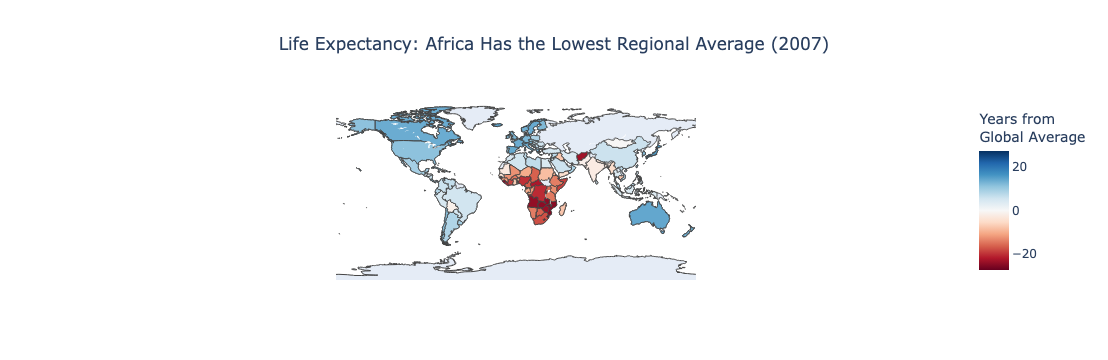

Global average life expectancy: 67.01 years
Lowest life expectancy country: Swaziland
Lowest country life expectancy: 39.61 years
Lowest average continent: Africa
Average life expectancy in Africa: 54.81 years


In [2]:
# Load Gapminder dataset for 2007
gm_2007 = px.data.gapminder().query("year == 2007").copy()

# Calculate global average life expectancy
global_mean = gm_2007["lifeExp"].mean()

# Calculate deviation from global average
gm_2007["deviation"] = gm_2007["lifeExp"] - global_mean

# Find the country with the lowest life expectancy
lowest_country = gm_2007.loc[gm_2007["lifeExp"].idxmin()]

# Find the continent with the lowest average life expectancy
continent_avg = gm_2007.groupby("continent")["lifeExp"].mean()

lowest_continent = continent_avg.idxmin()

# Create world choropleth map
fig = px.choropleth(
    gm_2007,
    locations="iso_alpha",
    color="deviation",
    hover_name="country",
    hover_data={
        "lifeExp": ":.2f",
        "deviation": ":.2f",
        "iso_alpha": False
    },
    color_continuous_scale="RdBu",
    color_continuous_midpoint=0,
    title=f"Life Expectancy: {lowest_continent} Has the Lowest Regional Average (2007)"
)


fig.update_layout(
    title_x=0.5,
    geo=dict(showframe=False, showcoastlines=True),
    coloraxis_colorbar_title="Years from<br>Global Average"
)

fig.show()

# Display findings
print(f"Global average life expectancy: {global_mean:.2f} years")
print(f"Lowest life expectancy country: {lowest_country['country']}")
print(f"Lowest country life expectancy: {lowest_country['lifeExp']:.2f} years")
print(f"Lowest average continent: {lowest_continent}")
print(f"Average life expectancy in {lowest_continent}: {continent_avg.min():.2f} years")

Interpretation:

The choropleth map displays the difference between each country's life expectancy and the global average in 2007. Countries below the global average are shown in red, while countries above the global average are shown in blue. The diverging colour scale is centred at zero, representing the global average. The map helps identify geographical inequalities in life expectancy across the world.

## Task 2 — Find your own GeoJSON

**What to build:** A choropleth using a GeoJSON file you find yourself online.

**Requirements:**
- Find a free GeoJSON file for any geography that interests you (country, region, city)
- Create or find a matching dataset with at least one numeric variable per region
- Build either a `px.choropleth` or `px.choropleth_mapbox` — state your choice and reason in the markdown cell below
- Correctly identify and set `featureidkey` by inspecting the GeoJSON properties
- Choose sequential or diverging scale — state your reason in the markdown cell below
- Insight title naming a geographic finding

**Where to find GeoJSON files:**
- [geojson.xyz](https://geojson.xyz/) — countries, cities, natural features
- [naturalearthdata.com](https://www.naturalearthdata.com/) — global admin boundaries
- [github.com/datasets/geo-countries](https://github.com/datasets/geo-countries) — country polygons
- Search: `[country name] [admin level] GeoJSON github` — most countries have free boundary files on GitHub

> 💡 Before plotting, always inspect your GeoJSON properties first:
> ```python
> print(my_geojson['features'][0]['properties'])
> ```
> The property name that matches your dataframe's location column is what goes in `featureidkey='properties.???'`


### Task 2 — Design decisions

**GeoJSON source:** *PublicaMundi US States GeoJSON – GitHub repository.*

**Chart type chosen** (`px.choropleth` or `px.choropleth_mapbox`) **and reason:**

*Your answer here* I chose px.choropleth because it provides a clear geographic representation of population differences across US states. It uses geographic boundaries and makes regional comparisons easy.

**Colour scale chosen** (sequential or diverging) **and reason:**

*Your answer here*
I chose a sequential colour scale (Blues) because population is a continuous numerical variable with values greater than zero. Darker shades represent states with larger populations, while lighter shades represent states with smaller populations.

GeoJSON properties:
{'name': 'Alabama', 'density': 94.65}

States not matched:
set()


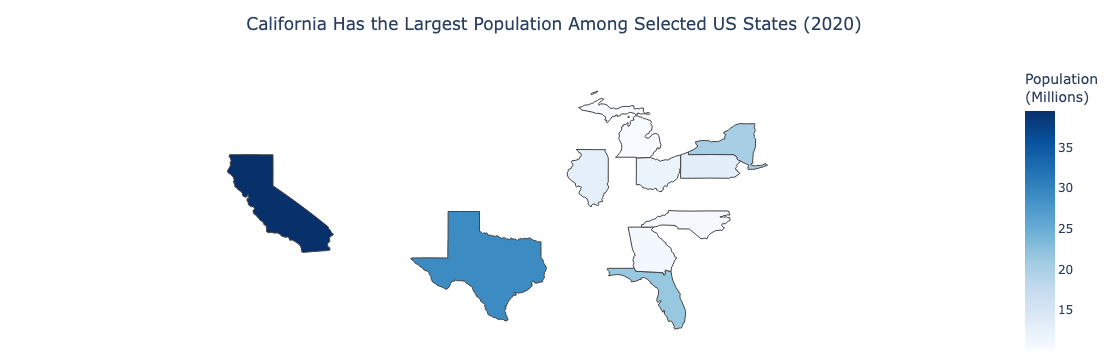


Population Analysis
-------------------
Highest population state: California
Population: 39,538,223
Number of states: 10


In [5]:
# Task 2
# YOUR CODE HERE

# Load your GeoJSON
# with open('your_file.geojson', 'r') as file:
#     my_geojson = json.load(file)

# Inspect the properties to find the right featureidkey
# print(my_geojson['features'][0]['properties'])

# Task 2: US States Population Choropleth

import pandas as pd
import plotly.express as px
import json
import requests

# Load GeoJSON file
geojson_url = "https://raw.githubusercontent.com/PublicaMundi/MappingAPI/master/data/geojson/us-states.json"

response = requests.get(geojson_url)
response.raise_for_status()

my_geojson = response.json()

# Inspect GeoJSON properties
print("GeoJSON properties:")
print(my_geojson["features"][0]["properties"])

# Create population dataset (2020 Census)
population_data = {
    "state": [
        "California",
        "Texas",
        "Florida",
        "New York",
        "Pennsylvania",
        "Illinois",
        "Ohio",
        "Georgia",
        "North Carolina",
        "Michigan"
    ],

    "population": [
        39538223,
        29145505,
        21538187,
        20201249,
        13002700,
        12812508,
        11799448,
        10711908,
        10439388,
        10077331
    ]
}

df = pd.DataFrame(population_data)

# Convert population into millions
df["population_millions"] = df["population"] / 1000000

# Check state names against GeoJSON
geojson_states = {
    feature["properties"]["name"]
    for feature in my_geojson["features"]
}

print("\nStates not matched:")
print(set(df["state"]) - geojson_states)

# Find the state with the highest population
highest_state = df.loc[df["population"].idxmax()]

# Create choropleth map
fig = px.choropleth(
    df,
    geojson=my_geojson,
    locations="state",
    featureidkey="properties.name",
    color="population_millions",
    hover_name="state",
    hover_data={
        "population": ":,",
        "population_millions": ":.2f"
    },
    color_continuous_scale="Blues",
    title="California Has the Largest Population Among Selected US States (2020)"
)

# Improve map appearance
fig.update_geos(
    fitbounds="locations",
    visible=False
)

fig.update_layout(
    title_x=0.5,
    coloraxis_colorbar_title="Population<br>(Millions)",
    margin={"r": 0, "t": 60, "l": 0, "b": 0}
)

fig.show()

# Display findings
print("\nPopulation Analysis")
print("-------------------")
print("Highest population state:", highest_state["state"])
print("Population:", f"{highest_state['population']:,}")
print("Number of states:", len(df))

Interpretation:

The choropleth map illustrates the population distribution across ten selected US states based on the 2020 Census. California has the largest population among the selected states, followed by Texas and Florida. The darker blue shades represent states with larger populations, while lighter shades indicate smaller populations.

The map demonstrates geographical differences in population distribution and helps identify the most populated states.